# Clonal vs. physiologic explanations of relapse phenomena

A catalogue of clinically observed resistance phenomena. For each one we first
ask whether **clonal selection** — a drug-sensitive clone $C_s$ and a
pre-existing resistant clone $C_r$, no $A,B$ circuit — can produce it, and at
what cost in assumptions. The physiologic (RPA) explanation will be added
alongside later.

The first group concerns the **slope of relapse** relative to pre-treatment
growth:

| phenomenon | clonal explanation |
|---|---|
| slower relapse | resistance carries a fitness cost, $r_r < r_s$ |
| complete response | partial resistance: the drug still kills $C_r$, faster than it grows |
| same-rate relapse | no fitness cost, $r_r = r_s$ |
| faster relapse | an unrelated high-fitness mutation in the resistant clone |

The basic model, with $u(t)=1$ while dosing:

$$\dot C_s = (r_s - \kappa\,u)\,C_s, \qquad \dot C_r = r_r\,C_r, \qquad C = C_s + C_r.$$

Its net growth rate $d\ln C/dt = (1-f)\,(r_s-\kappa u) + f\,r_r$, with
$f = C_r/C$, is a weighted mean of the clone rates. Before treatment $f \approx
f_0$ is small, so the tumor grows at $\approx r_s$. After treatment $f \to 1$,
so relapse grows at $r_r$. **The relapse slope is the resistant clone's net
growth rate under the drug** — $r_r$ when the drug leaves it alone. Every case
below follows from this.

Each panel shows the tumor size (red); the dashed black line is the same-rate
relapse of case 3, for comparison.

In [64]:
"""Relapse slope under clonal selection: slower, complete response, same, faster."""
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

PLOTS_DIR = Path("../plots")
PLOTS_DIR.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a matplotlib figure to PLOTS_DIR as a PDF."""
    if not name.lower().endswith(".pdf"):
        name = f"{name}.pdf"
    save_path = PLOTS_DIR / name
    fig.savefig(save_path, format="pdf", bbox_inches="tight")
    print(f"Figure saved to {save_path}")


# --- shared parameters (as in SI_clonal_resistance.ipynb) -------------------
r_s = 1.0                    # sensitive-clone growth rate = Figure 1's c1 (per week)
kappa, f0 = 3.0, 0.05        # kill rate while dosing; initial resistant fraction
t_rx, T = 2.0, 8.0           # treatment start; horizon (weeks)
FS = 10                      # label font size (ticks one smaller)
DRUG_SHADE = "#ececec"       # light grey background for "drug on"

t = np.linspace(0, T, 3201)
u = lambda s: 1.0 if s >= t_rx else 0.0     # continuous dosing from t_rx


def simulate(rhs, y0):
    """Integrate rhs(t, y) on the shared time grid."""
    return solve_ivp(rhs, [0, T], y0, max_step=0.005, rtol=1e-9, atol=1e-14,
                     dense_output=True).sol(t)


def growth_rates(C):
    """Pre-treatment rate (log-linear fit on [0, t_rx]) and peak post-treatment
    rate (max of d ln C/dt after the nadir), both per week."""
    lnC = np.log(C)
    pre = np.polyfit(t[t <= t_rx], lnC[t <= t_rx], 1)[0]
    rate = np.gradient(lnC, t)
    nadir = np.argmin(np.where(t >= t_rx, C, np.inf))
    return pre, rate[nadir:].max()


def relapse_panel(clones, title, name, reference=None):
    """Tumor size (log) through treatment, in the style of the main-text figure.

    clones: dict label -> trajectory; the total C (red) is their sum.
    reference: optional same-rate relapse, drawn as a dashed black line.
    """
    C = sum(clones.values())
    pre, peak = growth_rates(C)

    fig, ax = plt.subplots(figsize=(3.6, 2.7))
    ax.axvspan(t_rx, T, color=DRUG_SHADE, zorder=0)
    ax.plot(t, C, color='tab:red', lw=2.2, zorder=3)
    lo, hi = C.min(), C.max()
    if reference is not None:                         # same-rate relapse
        ax.plot(t, reference, color='k', lw=1.3, ls='--', zorder=4)
        lo, hi = min(lo, reference.min()), max(hi, reference.max())

    ax.set_yscale('log')
    ax.set_ylim(lo / 4, hi * 6)
    ax.set_xlim(0, T)
    ax.set_xticks(range(int(T) + 1))
    ax.set_xlabel('time (weeks)', fontsize=FS)
    ax.set_ylabel('tumor size (log)', fontsize=FS)
    ax.set_title(title, fontsize=FS + 1, pad=8)
    ax.tick_params(labelsize=FS - 1)
    ax.spines[['top', 'right']].set_visible(False)

    fig.tight_layout()
    save_fig(fig, name)
    print(f'{name}: g_pre = {pre:.3f}/wk, peak g_post = {peak:.3f}/wk '
          f'(ratio {peak / pre:.2f})')
    return fig


def two_clone(r_r, r_s=r_s, kappa=kappa):
    """Exponential two-clone model, no competition."""
    return lambda s, y: [(r_s - kappa * u(s)) * y[0], r_r * y[1]]


# Same-rate relapse (no fitness cost): the dashed reference on the other panels
C_same_rate = simulate(two_clone(r_s), [1 - f0, f0]).sum(axis=0)

## 1. Slower relapse — resistance carries a fitness cost

$r_r < r_s$: the resistant clone pays for resistance with slower division, so
once it dominates the tumor regrows more slowly than it grew before treatment.
Works as expected; the relapse rate is exactly $r_r$.

Figure saved to ../plots/clonal_relapse_slower.pdf
clonal_relapse_slower: g_pre = 0.984/wk, peak g_post = 0.500/wk (ratio 0.51)


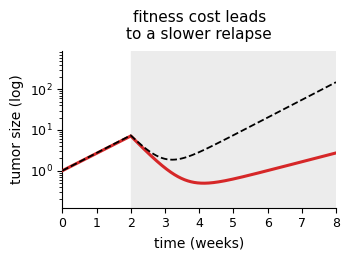

In [65]:
r_r_slow = 0.5 * r_s
Cs, Cr = simulate(two_clone(r_r_slow), [1 - f0, f0])
fig_slow = relapse_panel(
    {'sensitive': Cs, 'resistant': Cr},
    'fitness cost leads\nto a slower relapse',
    "clonal_relapse_slower", reference=C_same_rate)

## 2. Complete response — partial resistance

The resistant clone is only **partly** protected: the drug still kills it, at a
reduced rate $\kappa_r < \kappa$:

$$\dot C_r = (r_r - \kappa_r\,u)\,C_r.$$

If the residual kill outweighs its growth ($\kappa_r > r_r$), both clones
shrink under treatment. The tumor never relapses; it declines toward zero. Here
resistance halves the kill ($\kappa_r = \kappa/2$) at no fitness cost.

The decline has two phases:
* a fast drop while $C_s$ dies, at $r_s - \kappa$;
* a slower decline, at $r_r - \kappa_r$, once $C_r$ dominates.

Figure saved to ../plots/clonal_complete_response.pdf
clonal_complete_response: g_pre = 1.000/wk, peak g_post = -0.504/wk (ratio -0.50)
  net rate under drug: C_s -2.00/wk, C_r -0.50/wk; C(T)/C(t_rx) = 2.5e-03


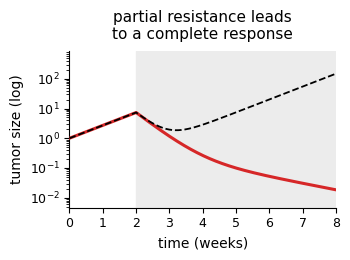

In [66]:
def partial_resistance(r_r, kappa_r, r_s=r_s, kappa=kappa):
    """Exponential two-clone model; the drug still kills Cr, at kappa_r < kappa."""
    return lambda s, y: [(r_s - kappa * u(s)) * y[0], (r_r - kappa_r * u(s)) * y[1]]


r_r_partial, kappa_r = r_s, 0.5 * kappa      # no fitness cost; resistance halves the kill
Cs, Cr = simulate(partial_resistance(r_r_partial, kappa_r), [1 - f0, f0])
fig_partial = relapse_panel(
    {'sensitive': Cs, 'resistant': Cr},
    'partial resistance leads\nto a complete response',
    "clonal_complete_response", reference=C_same_rate)
print(f'  net rate under drug: C_s {r_s - kappa:+.2f}/wk, C_r {r_r_partial - kappa_r:+.2f}/wk; '
      f'C(T)/C(t_rx) = {(Cs + Cr)[-1] / (Cs + Cr)[t <= t_rx][-1]:.1e}')

## 3. Same-rate relapse — no fitness cost

$r_r = r_s$: the relapse runs exactly parallel to the pre-treatment curve. Works
as expected. This is the dashed reference on the other panels.

Figure saved to ../plots/clonal_relapse_same.pdf
clonal_relapse_same: g_pre = 1.000/wk, peak g_post = 1.000/wk (ratio 1.00)


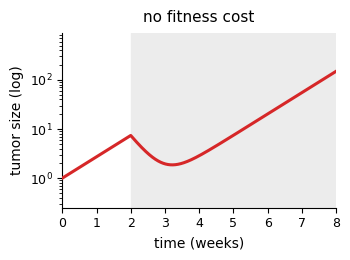

In [67]:
Cs, Cr = simulate(two_clone(r_s), [1 - f0, f0])
fig_same = relapse_panel(
    {'sensitive': Cs, 'resistant': Cr},
    'no fitness cost',
    "clonal_relapse_same")

## 4. Faster relapse — a high-fitness mutation at a set time

With $r_r \le r_s$, faster relapse needs a lineage fitter than the bulk tumor.
Here a fitter lineage $C_m$ ($r_m > r_s$) arises by a mutation unrelated to the
drug. Instead of a mutation *rate* we fix the event: at $t_{mut}$ one resistant
cell acquires the mutation. A mutant arising in a sensitive cell would be killed
by the drug, so it must arise in $C_r$ and inherit its resistance:

$$\dot C_s = (r_s - \kappa u)\,C_s, \qquad \dot C_r = r_r C_r, \qquad
  \dot C_m = r_m C_m, \qquad C_m(t_{mut}^+) = \text{one cell}.$$

Units: $C = 1$ is a $10^9$-cell tumor (≈1 cm³, just detectable), so one cell
is $10^{-9}$.

The mutant overtakes $C_r$ after $\tau = \ln\bigl(C_r(t_{mut})/C_m(t_{mut})\bigr)
/ (r_m - r_r)$. With one cell in a $10^9$-cell tumor, the logarithm is ≈18–20.
To bring the faster phase **inside the 8-week window**, both levers are needed:

* **Mutate early**, before treatment ($t_{mut} = 1$ week), while $C_r$ is still
  small. A mutation during treatment, when $C_r$ has already expanded, comes
  later still.
* **Grow much faster**: $r_m = 5\,r_s$. A twofold advantage takes ~20 weeks to
  show (table below).

With these values relapse runs at $r_r$ at first, then bends upward to $r_m$
around week 5–6: an aggressive relapse, $g_{post} > g_{pre}$.

**The price:**
* A fivefold growth-rate advantage is extreme.
* By week 8 the tumor holds ~$10^{15}$ cells, far past a lethal burden of
  ~$10^{12}$. Exponential growth at $5\,r_s$ cannot be sustained.
* The alternative lever is a larger seed: a fitter resistant lineage already
  well established before treatment. That is just resistance carried by a
  lineage fitter than the bulk tumor, $r_r > r_s$.

Figure saved to ../plots/clonal_relapse_timed_mutation.pdf
clonal_relapse_timed_mutation: g_pre = 1.000/wk, peak g_post = 5.000/wk (ratio 5.00)
  mutant overtakes C_r at week 5.7; tumor at week 8 ~2e+15 cells (lethal ~1e12)

t_mut   r_m/r_r   takeover (week)   tumor at takeover (cells)
0.0     2                  17.7                  5.0e+15
0.0     3                   8.9                  7.1e+11
0.0     4                   5.9                  3.7e+10   <- within 8 weeks
0.0     5                   4.4                  8.4e+09   <- within 8 weeks
0.0     6                   3.5                  3.5e+09   <- within 8 weeks
1.0     2                  19.7                  3.7e+16
1.0     3                  10.4                  3.2e+12
1.0     4                   7.2                  1.4e+11   <- within 8 weeks
1.0     5                   5.7                  2.9e+10   <- within 8 weeks
1.0     6                   4.7                  1.2e+10   <- within 8 weeks
2.0     2              

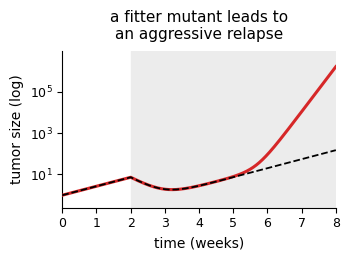

In [68]:
N_cells = 1e9                     # cells in a tumor of size C = 1
one_cell = 1 / N_cells
r_r_mut, r_m = r_s, 5.0 * r_s     # resistant clone: no cost; mutant 5x faster
t_mut = 1.0                       # mutation time (weeks), before treatment starts


def timed_mutation(t_mut=t_mut, seed=one_cell, r_r=r_r_mut, r_m=r_m):
    """Two-clone model until t_mut, then `seed` of Cr becomes a fitter mutant Cm."""
    rhs = lambda s, y: [(r_s - kappa * u(s)) * y[0], r_r * y[1], r_m * y[2]]
    opts = dict(max_step=0.005, rtol=1e-9, atol=1e-20)
    before = solve_ivp(rhs, [0, t_mut], [1 - f0, f0, 0.0], dense_output=True, **opts)
    y_mut = before.y[:, -1] + np.array([0.0, -seed, seed])
    after = solve_ivp(rhs, [t_mut, T], y_mut, dense_output=True, **opts)
    early = t < t_mut
    y = np.empty((3, t.size))
    y[:, early] = before.sol(t[early])
    y[:, ~early] = after.sol(t[~early])
    return y


def takeover(t_mut, r_m, seed=one_cell, r_r=r_r_mut):
    """Week at which Cm = Cr, and the tumor size (cells) by then.
    Cr is f0*exp(r_r*t) whether or not the drug is on (it is drug-blind)."""
    Cr_mut = f0 * np.exp(r_r * t_mut)
    tau = np.log(Cr_mut / seed) / (r_m - r_r)
    return t_mut + tau, 2 * Cr_mut * np.exp(r_r * tau) * N_cells


Cs, Cr, Cm = timed_mutation()
fig_mut = relapse_panel(
    {'sensitive': Cs, 'resistant': Cr, 'mutant': Cm},
    'a fitter mutant leads to\nan aggressive relapse',
    "clonal_relapse_timed_mutation", reference=C_same_rate)

week, cells = takeover(t_mut, r_m)
print(f'  mutant overtakes C_r at week {week:.1f}; tumor at week {T:.0f} '
      f'~{(Cs + Cr + Cm)[-1] * N_cells:.0e} cells (lethal ~1e12)')

print('\nt_mut   r_m/r_r   takeover (week)   tumor at takeover (cells)')
for tm in [0.0, 1.0, 2.0, 3.0]:
    for ratio in [2, 3, 4, 5, 6]:
        week, cells = takeover(tm, ratio * r_r_mut)
        print(f'{tm:<7} {ratio:<9} {week:13.1f} {cells:24.1e}'
              f'{"   <- within 8 weeks" if week <= T else ""}')

## 5. Rechallenge — the sensitive clone takes the tumor back during a drug holiday

Clinically, a tumor that relapsed on a drug often responds to the **same drug
again** after a treatment-free period. The clonal explanation: resistance has a
fitness cost $c = r_s - r_r$. During the holiday the cheaper sensitive clone
outgrows the resistant one, so the second course meets a re-sensitized tumor.

The catch is an asymmetry in rates. On the drug, the resistant/sensitive ratio
$C_r/C_s$ grows at $\kappa - c$. Off the drug, it shrinks at only $c$. To undo
one course, the holiday must last about $(\kappa - c)/c$ times as long as the
course. Section 1's cost ($c = 0.5$) would need a holiday 5× the course, and
untuned, a 3-week holiday after a 3-week course gave no second response at all.

To see a clear effect we tune it:
* **a larger cost**, $r_r = 0.3\,r_s$ ($c = 0.7\,r_s$, ratio ≈ 3.3);
* **courses stopped soon after relapse begins**;
* **a holiday 3× the course.**

To resemble the main-text rechallenge figure, all rates are scaled by 0.4, so
the tumor grows ~50× over 10 weeks before treatment. This only stretches time.
Treatment starts at week 10 and each course lasts 10 weeks, as in that figure.
The holiday, however, must last **30 weeks** instead of 10.

The figure shows the resistant fraction (top) and the tumor (bottom). The
dashed line replays the first course from the start of the second: this is what a
fully recovered response would look like.

In [71]:
# All rates scaled by 0.4 so the tumor grows ~50x over the 10 weeks before
# treatment, as in the reference figure. This only stretches time by 2.5x.
rate_scale = 0.4
r_s_rc = rate_scale * r_s             # sensitive clone
r_r_rc = 0.3 * r_s_rc                 # resistant clone: 70% fitness cost
kappa_rc = rate_scale * kappa         # kill rate while dosing
t_rx_rc = 10.0                        # first course starts (weeks)
t_on_rc, t_off_rc = 10.0, 30.0        # course and holiday lengths (weeks)


def rechallenge_schedule(t_on=t_on_rc, t_off=t_off_rc, start=t_rx_rc):
    """Two courses of length t_on separated by a holiday of length t_off."""
    blocks = [(start, start + t_on), (start + t_on + t_off, start + 2 * t_on + t_off)]
    return blocks, blocks[1][1] + 5.0                   # courses, horizon


def simulate_rechallenge(r_r=r_r_rc, t_on=t_on_rc, t_off=t_off_rc):
    """Two drug-blind-resistant clones under the rechallenge schedule."""
    blocks, T_ = rechallenge_schedule(t_on, t_off)
    u_ = lambda s: 1.0 if any(a <= s < b for a, b in blocks) else 0.0
    t_ = np.linspace(0, T_, int(100 * T_) + 1)
    rhs = lambda s, y: [(r_s_rc - kappa_rc * u_(s)) * y[0], r_r * y[1]]
    Cs, Cr = solve_ivp(rhs, [0, T_], [1 - f0, f0], max_step=0.005, rtol=1e-9,
                       atol=1e-14, dense_output=True).sol(t_)
    return t_, Cs, Cr, blocks


def course_stats(t_, Cs, Cr, blocks):
    """Per course: resistant fraction at its start and the tumor nadir as a
    fraction of the size at its start."""
    C = Cs + Cr
    stats = []
    for a, b in blocks:
        m = (t_ >= a) & (t_ <= b)
        stats.append(((Cr / C)[m][0], C[m].min() / C[m][0]))
    return stats


def rechallenge_panel(t_, Cs, Cr, blocks, title, name):
    """Resistant fraction on top, tumor size (log) below, with the first course
    replayed (dashed) from the start of the second."""
    C = Cs + Cr
    (a1, b1), (a2, _) = blocks
    i1, i2 = np.searchsorted(t_, a1), np.searchsorted(t_, a2)
    n = np.searchsorted(t_, b1) - i1                    # samples in one course
    replay = np.full_like(C, np.nan)
    replay[i2:i2 + n] = C[i1:i1 + n] * C[i2] / C[i1]

    fig, axes = plt.subplots(2, 1, figsize=(4.8, 3.6), sharex=True,
                             gridspec_kw={'height_ratios': [1, 1.6]})
    for ax in axes:
        for a, b in blocks:
            ax.axvspan(a, b, color=DRUG_SHADE, zorder=0)
        ax.set_xlim(0, t_[-1])
        ax.set_xticks(range(0, int(t_[-1]) + 1, 10))
        ax.tick_params(labelsize=FS - 1)
        ax.spines[['top', 'right']].set_visible(False)

    axes[0].plot(t_, Cr / C, color='tab:purple', lw=2.2, zorder=3)
    axes[0].set_ylim(-0.05, 1.1)
    axes[0].set_yticks([0, 1])
    axes[0].set_ylabel('resistant\nfraction', fontsize=FS)
    # axes[0].set_title(title, fontsize=FS + 1, pad=8)

    axes[1].plot(t_, C, color='tab:red', lw=2.2, zorder=3)
    # axes[1].plot(t_, replay, color='k', lw=1.3, ls='--', zorder=4)
    axes[1].set_yscale('log')
    axes[1].set_ylabel('tumor size (log)', fontsize=FS)
    axes[1].set_xlabel('time (weeks)', fontsize=FS)

    fig.tight_layout(h_pad=0.4)
    save_fig(fig, name)
    for k, (f_start, nadir) in enumerate(course_stats(t_, Cs, Cr, blocks), 1):
        print(f'  course {k}: resistant fraction at start {f_start:.2f}, '
              f'tumor nadir {nadir:.3f}x the size at course start')
    return fig

**Result: a second response, but only after a long holiday.**

* **First course (weeks 10–20):** the tumor shrinks 100× (to 0.010×) and the
  resistant fraction climbs to ~1. The tumor then begins to relapse on
  treatment, though only slightly (1.1×).
* **Holiday (weeks 20–50):** the sensitive clone regrows and the resistant
  fraction falls back to 0.01.
* **Second course (weeks 50–60):** the tumor shrinks 50× (to 0.020×), nearly
  matching the first response.

**Where it departs from the main-text figure** (tables below):
* **The holiday must be 30 weeks, not 10.** A 10-week holiday gives a
  second response of only 0.89×.
* **The tumor regrows ~5000× during that holiday**, to ~3000× its starting
  size.
* **The relapse on treatment is barely visible.** A longer course shows a
  clearer relapse but leaves a more resistant tumor. With a 15-week course the
  relapse is 1.9×, and the 30-week holiday then recovers only a 0.64×
  response. A search over the cost, kill rate, course and holiday lengths
  found no setting with both a relapse of 2× or more and a second response
  below 0.13×. Even 0.13× needs a 40-week holiday and a million-fold
  regrowth.


Figure saved to ../plots/clonal_rechallenge.pdf
  course 1: resistant fraction at start 0.00, tumor nadir 0.010x the size at course start
  course 2: resistant fraction at start 0.01, tumor nadir 0.020x the size at course start

holiday (wk)   resistant fraction at course 2   course-2 nadir   course-1 nadir
5                                0.89            1.000            0.010
10                               0.66            0.890            0.010
15                               0.32            0.523            0.010
20                               0.10            0.204            0.010
25                               0.03            0.066            0.010
30                               0.01            0.020            0.010
35                               0.00            0.006            0.010

course (wk)   relapse on course 1   resistant fraction at course 2   course-2 nadir
7.5                      1.00x                     0.00                0.004
10.0                     

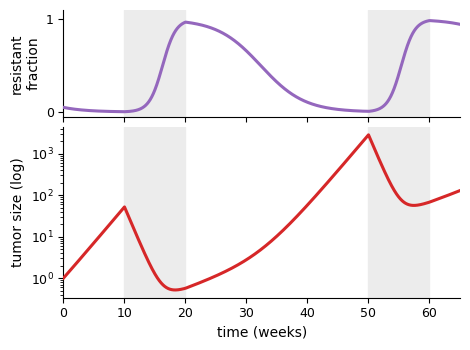

In [72]:
t_rc, Cs, Cr, rc_blocks = simulate_rechallenge()
fig_rc = rechallenge_panel(t_rc, Cs, Cr, rc_blocks,
                           'fitness cost: the sensitive clone\nregrows during the holiday',
                           "clonal_rechallenge")

# How long must the holiday be? Same course, varying holiday.
print('\nholiday (wk)   resistant fraction at course 2   course-2 nadir   course-1 nadir')
for t_off in [5, 10, 15, 20, 25, 30, 35]:
    stats = course_stats(*simulate_rechallenge(t_off=t_off))
    print(f'{t_off:<14} {stats[1][0]:22.2f} {stats[1][1]:16.3f} {stats[0][1]:16.3f}')

# The trade-off: a longer course shows a clearer relapse, but leaves the tumor
# more resistant, so the same 30-week holiday recovers less.
print('\ncourse (wk)   relapse on course 1   resistant fraction at course 2   course-2 nadir')
for t_on in [7.5, 10, 12.5, 15]:
    t_, Cs_, Cr_, blocks = simulate_rechallenge(t_on=t_on)
    C_ = Cs_ + Cr_
    m = (t_ >= blocks[0][0]) & (t_ <= blocks[0][1])
    stats = course_stats(t_, Cs_, Cr_, blocks)
    print(f'{t_on:<13.1f} {C_[m][-1] / C_[m].min():15.2f}x {stats[1][0]:24.2f} {stats[1][1]:20.3f}')